In [39]:
# Built-in modules
import math

# Imports from Qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate
from qiskit.visualization import plot_distribution
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Imports from qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler


def grover_oracle(marked_states):
    """Build a Grover oracle for multiple marked states

    Here we assume all input marked states have the same number of bits

    Parameters:
        marked_states (str or list): Marked states of oracle

    Returns:
        QuantumCircuit: Quantum circuit representing Grover oracle
    """
    if not isinstance(marked_states, list):
        marked_states = [marked_states]
    # Compute the number of qubits in circuit
    num_qubits = len(marked_states[0])

    qc = QuantumCircuit(num_qubits)
    # Mark each target state in the input list
    for target in marked_states:
        # Flip target bit-string to match Qiskit bit-ordering
        rev_target = target[::-1]
        # Find the indices of all the '0' elements in bit-string
        zero_inds = [
            ind
            for ind in range(num_qubits)
            if rev_target.startswith("0", ind)
        ]
        # Add a multi-controlled Z-gate with pre- and post-applied X-gates (open-controls)
        # where the target bit-string has a '0' entry
        if zero_inds:
            qc.x(zero_inds)
        qc.compose(MCMTGate(ZGate(), num_qubits - 1, 1), inplace=True)
        if zero_inds:
            qc.x(zero_inds)
    return qc

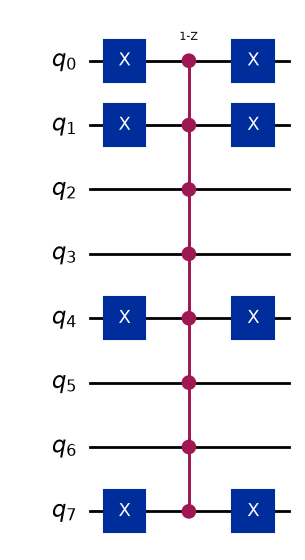

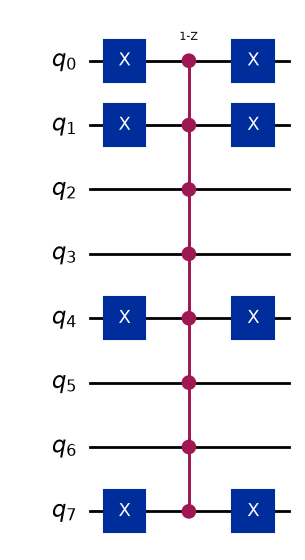

In [40]:
marked_states = ["01101100"]

oracle = grover_oracle(marked_states)
oracle.draw(output="mpl", style="iqp")

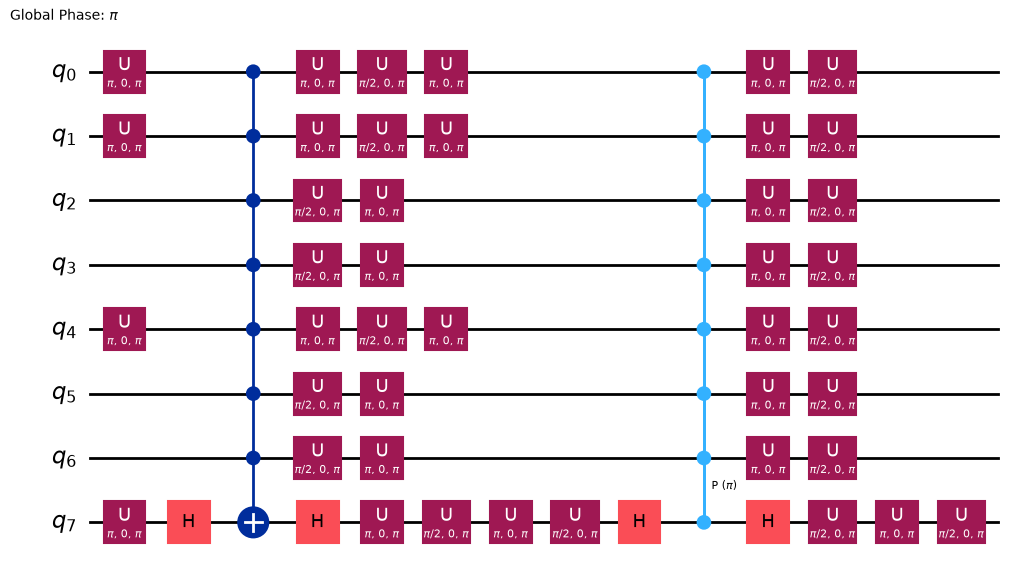

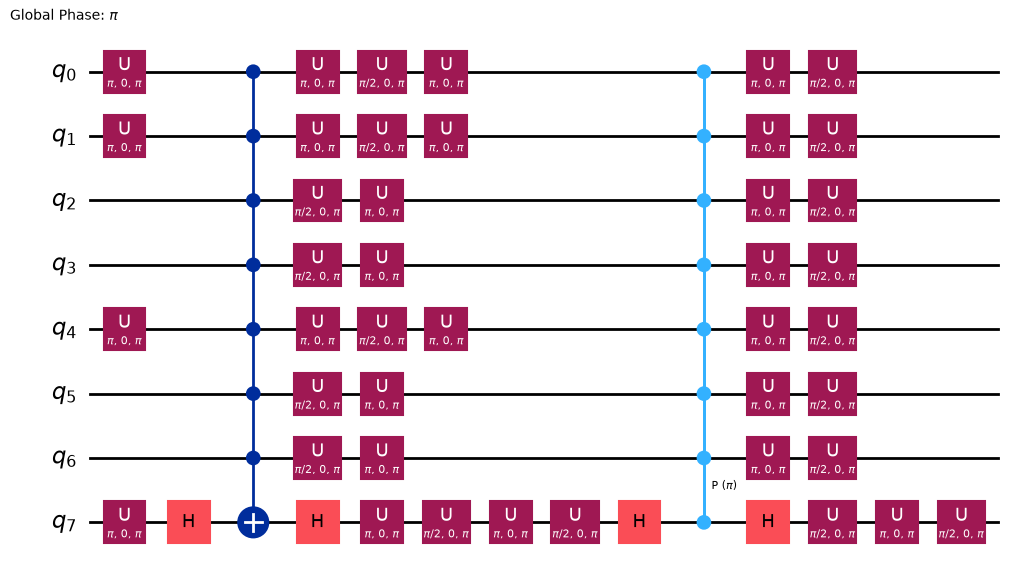

In [41]:
grover_op = grover_operator(oracle)
grover_op.decompose().draw(output="mpl", style="iqp")

In [42]:
optimal_num_iterations = math.floor(
    math.pi
    / (4 * math.asin(math.sqrt(len(marked_states) / 2**grover_op.num_qubits)))
)

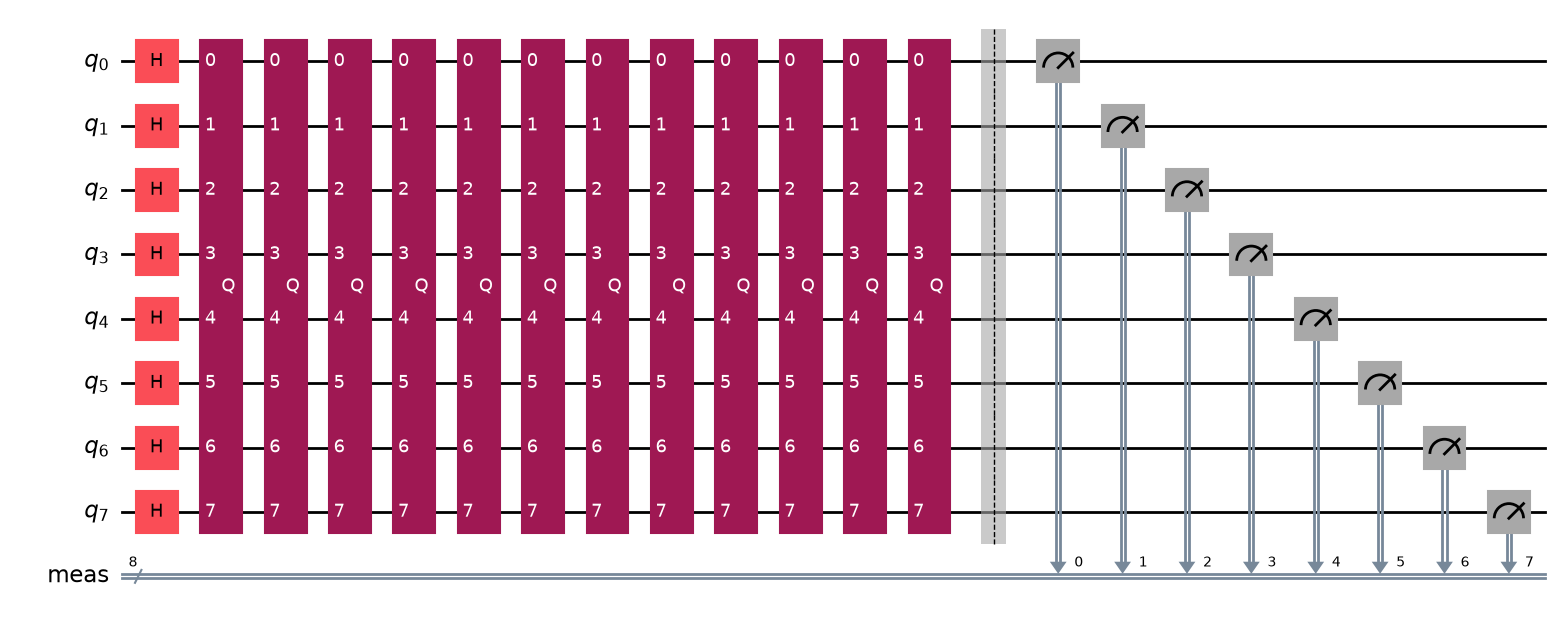

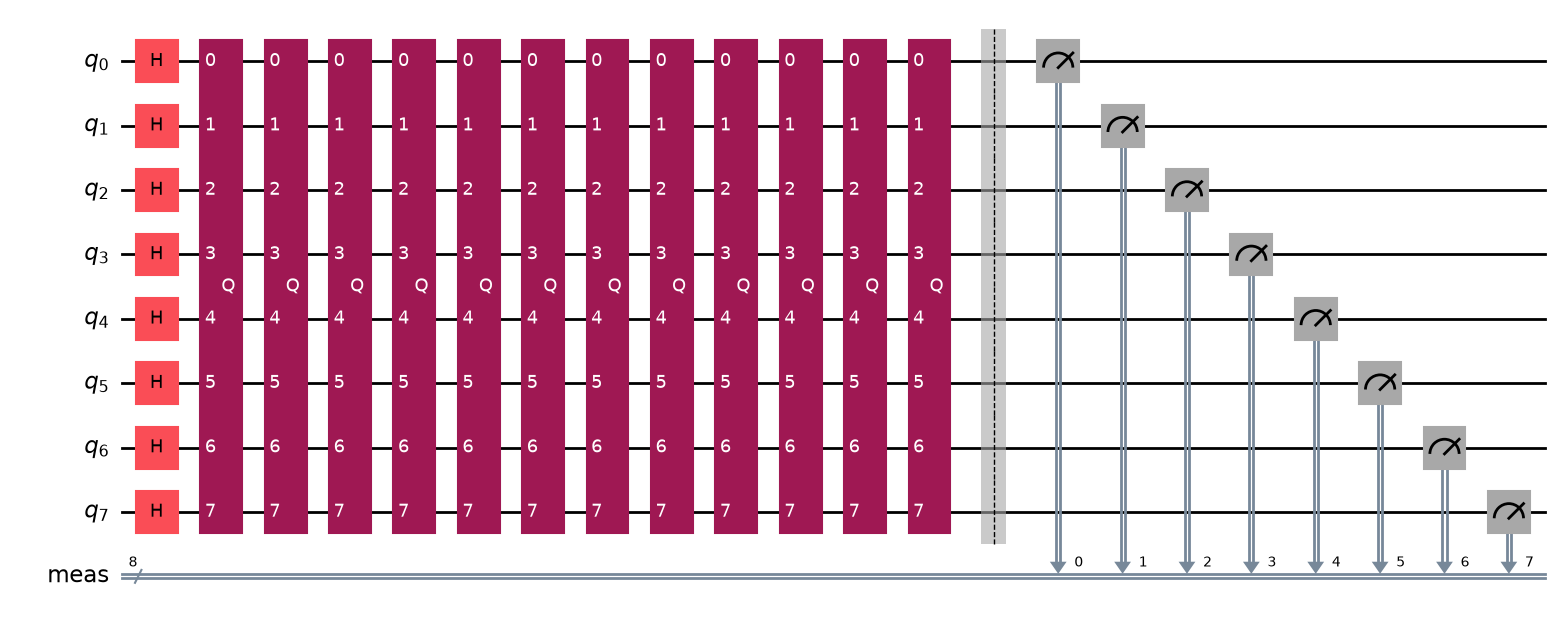

In [43]:
qc = QuantumCircuit(grover_op.num_qubits)
# Create even superposition of all basis states
qc.h(range(grover_op.num_qubits))
# Apply Grover operator the optimal number of times
qc.compose(grover_op.power(optimal_num_iterations), inplace=True)
# Measure all qubits
qc.measure_all()
qc.draw(output="mpl", style="iqp")

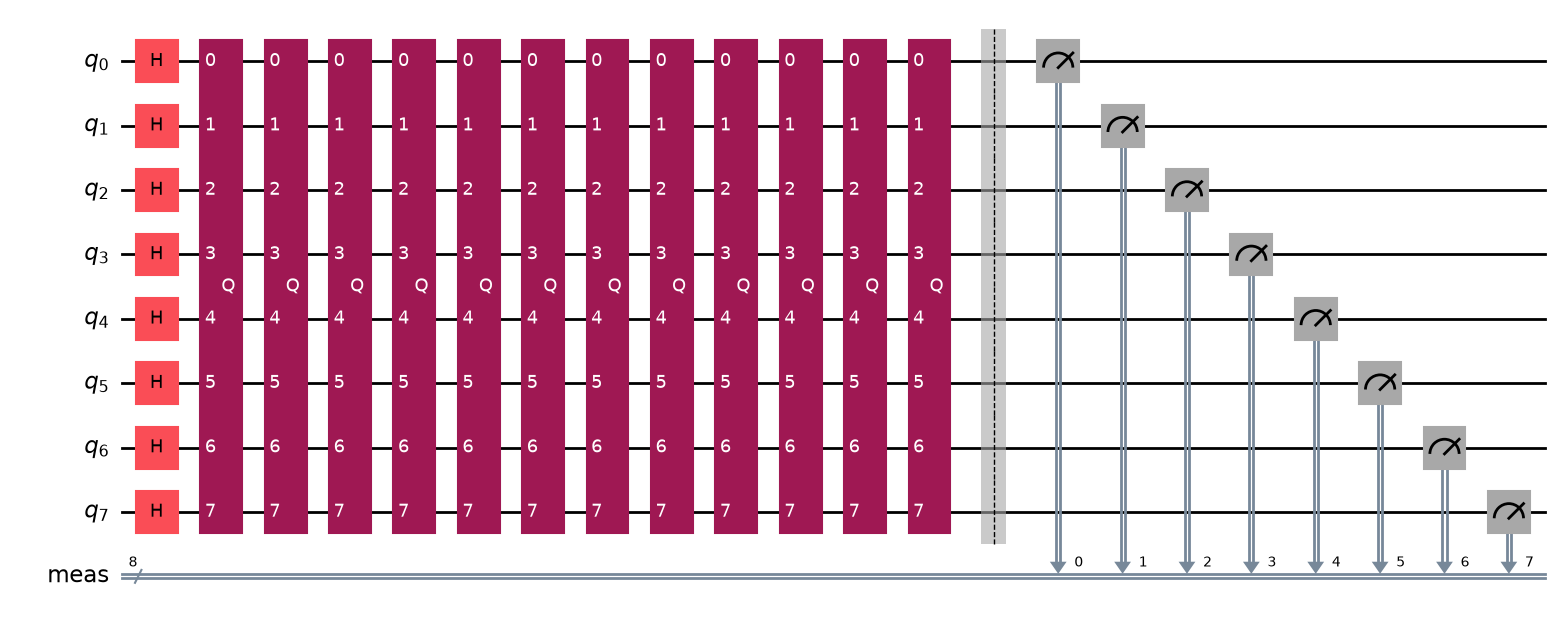

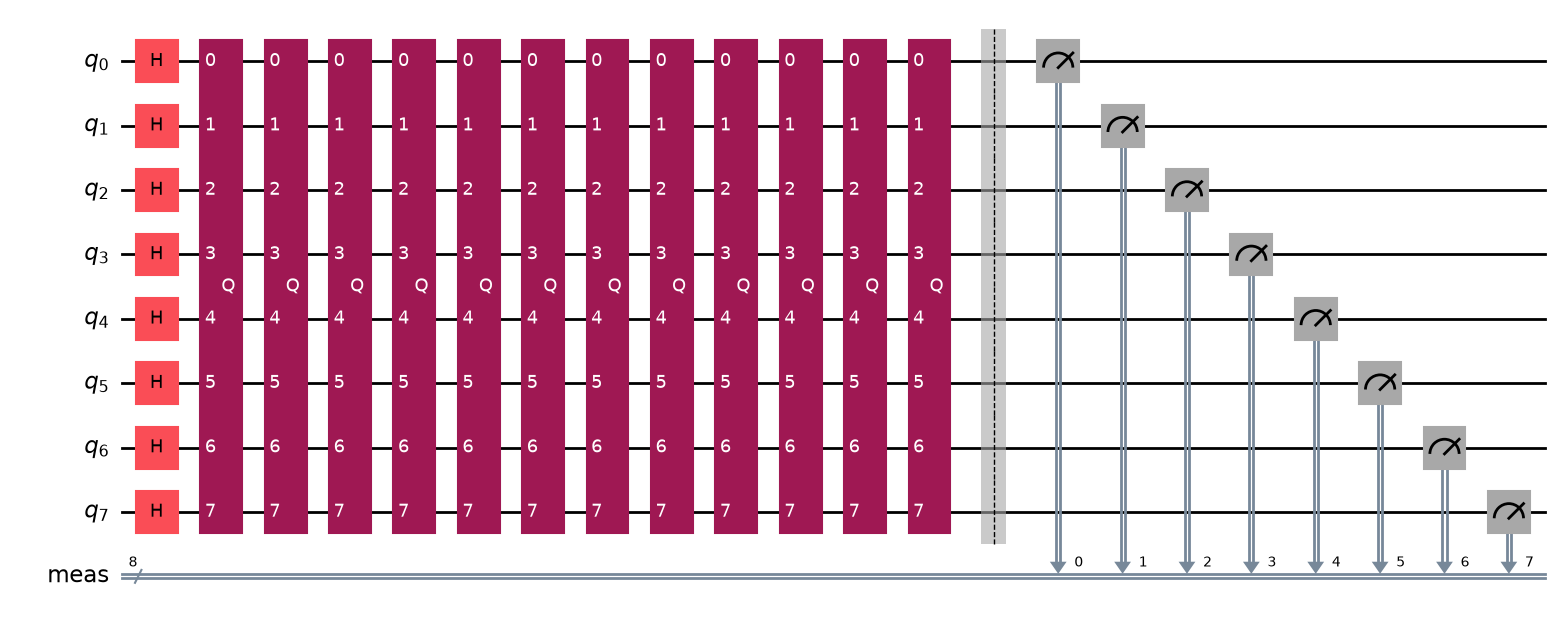

In [44]:
pm = generate_preset_pass_manager(optimization_level=3)
circuit_isa = pm.run(qc)
circuit_isa.draw(output="mpl", idle_wires=False, style="iqp")

In [45]:
service = QiskitRuntimeService()

backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=127,
)

In [46]:
from qiskit_aer import AerSimulator
from qiskit import transpile

# Use the IBM backend you selected earlier
noisy_simulator = AerSimulator.from_backend(backend)

# Transpile for the simulator's supported gates and connectivity
circuit_noisy = transpile(circuit_isa, noisy_simulator, optimization_level=3)

# Run locally with noise, not on IBM hardware
result = noisy_simulator.run(
    circuit_noisy,
    shots=10_000,
).result()

dist = result.get_counts()

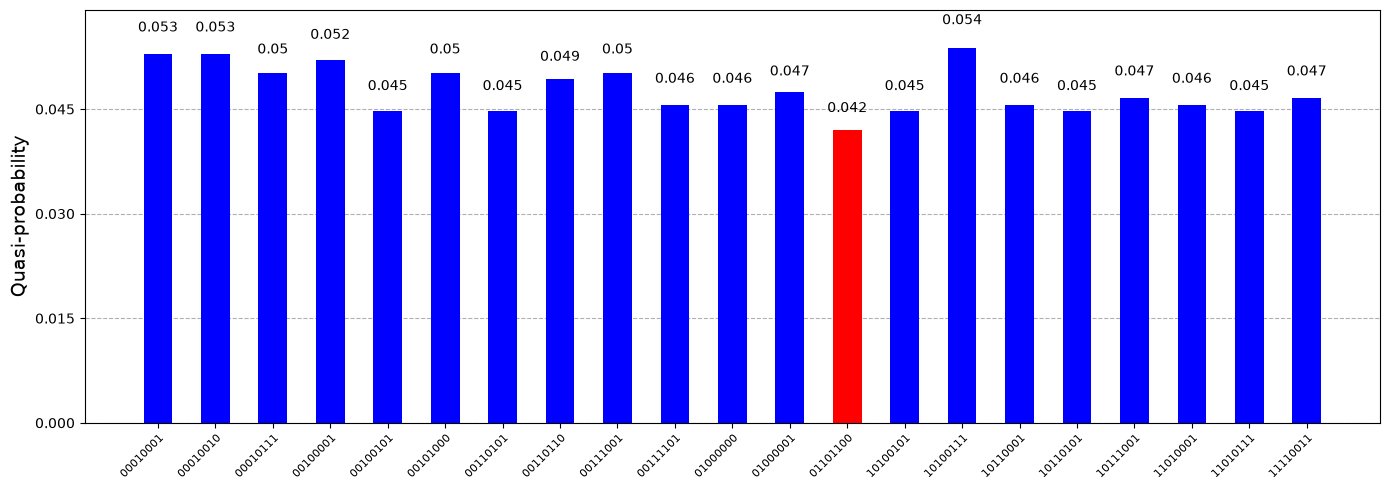

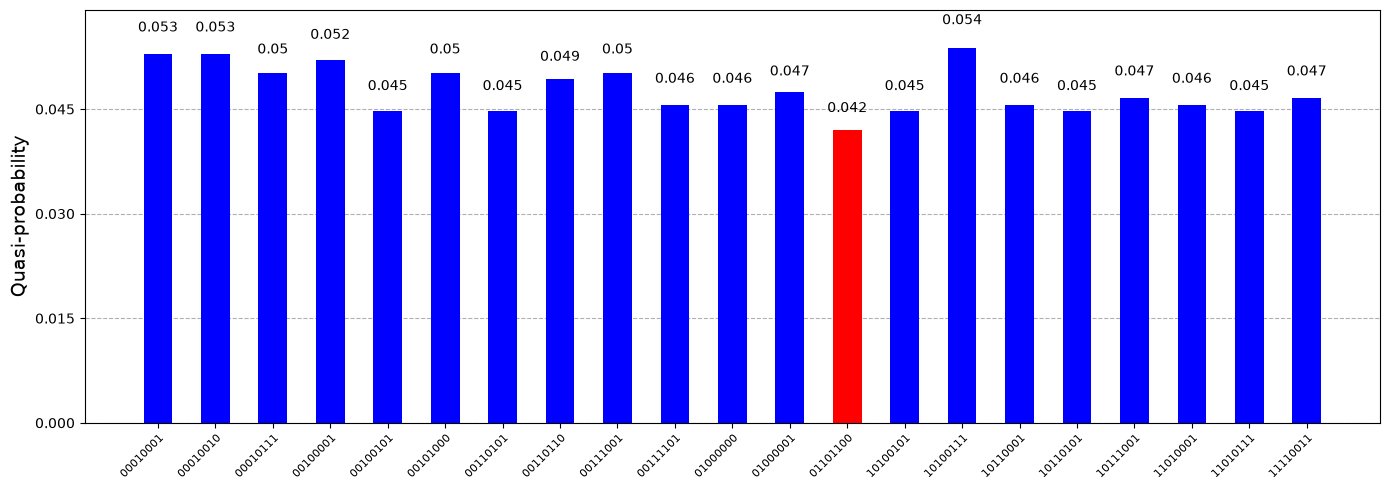

In [49]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_distribution

%matplotlib inline

# Bitstrings that must appear in red
red_states = marked_states

# Get the 20 most frequent outcomes
top_20 = dict(sorted(dist.items(), key=lambda item: item[1], reverse=True)[:20])

# Force all red states into the selection
for state in red_states:
    if state in dist:
        top_20[state] = dist[state]

# Plot the selected outcomes
fig = plot_distribution(top_20, figsize=(14, 5), color='blue')

# Color the specified states red
ax = fig.axes[0]
for bar, label in zip(ax.patches, [tick.get_text() for tick in ax.get_xticklabels()]):
    if label in red_states:
        bar.set_facecolor('red')

ax.tick_params(axis='x', labelrotation=45, labelsize=8)
plt.tight_layout()
display(fig)